# Hiérarchie de concepts grammaticaux (EWT)

**Question.** Quand on retire l'encodage le plus direct d'un concept spécifique, les supports suivants de la boucle s'appuient-ils sur un concept **plus général** qui le contient ? Par exemple, pour « verbe au passif » : S₁ contiendrait des neurones propres au passif, et les niveaux suivants des neurones qui codent « verbe » en général.

**Données.** Le corpus Universal Dependencies English Web Treebank (EWT), annoté à la main au niveau du mot (catégorie grammaticale, temps, nombre, voix, …). Gurnee et al. l'utilisent pour leurs features linguistiques ; leur figure 5c montre justement un neurone « verbe passif » à fort rappel et un neurone « verbe » à forte précision, mais sans analyse de hiérarchie.

**Représentation.** Pour chaque mot, l'activation des 2 048 neurones MLP (post-GELU) d'une couche de Pythia-70m, prise au **dernier token** du mot (le moment où le modèle a lu le mot entier). Gurnee et al. étiquettent tous les tokens d'un mot ; on garde un seul token par mot pour éviter de compter un mot plusieurs fois.

**Paires parent → enfant testées.**

| Enfant | Parent |
|---|---|
| verbe au passif (`Voice=Pass`) | verbe (`VERB`) |
| verbe au passé, forme finie (`Tense=Past`, `VerbForm=Fin`) | verbe |
| gérondif (`VerbForm=Ger`) | verbe |
| nom pluriel (`Number=Plur`) | nom (`NOUN`) |
| pronom personnel (`PronType=Prs`) | pronom (`PRON`) |

**Deux façons de définir les négatifs** pour chaque enfant :
- **global** : l'enfant contre tous les autres mots. Les neurones du parent aident à prédire l'enfant (un verbe passif est d'abord un verbe). C'est là qu'on cherche la hiérarchie.
- **within** : l'enfant contre les autres membres du parent (passif contre autres verbes), comme Gurnee et al. pour la voix. Les neurones du parent n'aident plus : c'est le contrôle.

On lance aussi la boucle sur les parents eux-mêmes (`is_verb`, `is_noun`, `is_pron`) pour comparer leurs supports à ceux des enfants.

**Prérequis.** `build_ewt_dataset.py` puis `extract_ewt_activations.py` (voir le README).

In [22]:
import os, sys, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import f1_score, roc_auc_score, log_loss, precision_score, recall_score

sys.path.insert(0, os.path.abspath("../.."))
from picpy.calibration import BinomialCalibrator
from picpy import LogisticRegression
from picpy.penalties import SCADPenalty
from picpy.selection import RecursiveSelection

MODEL = "pythia-70m"
ACT_DIR = f"cached_activations/{MODEL}/ewt"
LAYERS = [0, 1, 2, 3, 4, 5]   # couches analysées
MAX_ITER = 100           # itérations max de la boucle 
TASKS_RUN = ["is_pron"]   # tâches lancées (tâches contextuelles, voir la définition des tâches)
KEEP_ALL_POS = True      # garder tous les positifs (au plus 20 % du jeu), comme Gurnee et al.
OUT = f"results/{MODEL}/ewt_maxiter{MAX_ITER}"   # dossier séparé : les résultats à 10 itérations restent intacts
ALPHA, N_SIMU = 0.05, 2000
N_TASK_MAX = 15000       # taille max d'un jeu de données par tâche (Gurnee et al. : 25 000)
TEST_FRAC, SEED = 0.3, 0
K_SWEEP = [1, 2, 4, 8, 16, 32, 64]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT, exist_ok=True)

W = pd.read_csv(f"{ACT_DIR}/words.csv", keep_default_na=False)
_cache = {}


def load_layer(l):
    """Activations (n_mots x 2048) en float16, gardées en mémoire."""
    if l not in _cache:
        _cache[l] = np.load(f"{ACT_DIR}/{l}.npy")
    return _cache[l]


def cohen_d(X, y):
    y = np.asarray(y, bool)
    m1, m0 = X[y].mean(0), X[~y].mean(0)
    return (m1 - m0) / np.sqrt(0.5 * (X[y].var(0) + X[~y].var(0)) + 1e-8)


print(f"{len(W)} mots, device = {DEVICE}")
display(W.upos.value_counts().head(12).to_frame("mots"))

50000 mots, device = cuda


,mots
upos,
NOUN,8787
PUNCT,5959
VERB,5659
ADP,4551
PRON,4281
DET,3919
ADJ,3334
PROPN,3217
AUX,2700


## Définition des tâches

Chaque tâche est un problème binaire : `pos` (le concept) contre `neg`. Le tableau donne le nombre de positifs et de négatifs. Les enfants rares (le passif représente environ 1 % des mots) ont peu de positifs : vérifier qu'il y en a au moins quelques centaines avant d'interpréter.

**Tâche contextuelle `past_vs_participle`.** Toutes les tâches ci-dessus se devinent surtout à partir du mot seul (AUC de 0,90 à 1,00 en regardant seulement la forme du mot). On ajoute donc une tâche où le mot ne suffit pas : le **passé simple** (`Tense=Past`, `VerbForm=Fin`, « I *worked* ») contre le **participe passé** (`VerbForm=Part`, « I have *worked* », « it was *worked* »). La forme est souvent identique, et seul le contexte (la présence d'un auxiliaire) tranche : le mot seul ne donne qu'une AUC de 0,83. Si un ordre entre couches existe, c'est sur ce type de concept qu'il devrait apparaître, l'information de contexte étant rassemblée au fil des couches.

**Deuxième tâche contextuelle `passive_vs_active_participle`.** Parmi les participes passés, le **passif** (`Voice=Pass`, « it was *written* ») contre l'**actif** (« she has *written* »). Le mot est le même ; seul l'auxiliaire (*be* contre *have*) et la structure de la phrase tranchent. Le mot seul donne une AUC d'environ 0,85. Cette tâche sert à vérifier que le schéma observé sur `past_vs_participle` (contexte dans les couches intermédiaires, couche 0 au niveau du mot seul) se répète sur un autre concept contextuel.

In [23]:
up = W.upos.to_numpy()
PARENTS = {"VERB": up == "VERB", "NOUN": up == "NOUN", "PRON": up == "PRON"}
CHILDREN = {
    "verb_passive": (PARENTS["VERB"] & (W.Voice == "Pass").to_numpy(), "VERB"),
    "verb_past": (PARENTS["VERB"] & (W.Tense == "Past").to_numpy() & (W.VerbForm == "Fin").to_numpy(), "VERB"),
    "verb_gerund": (PARENTS["VERB"] & (W.VerbForm == "Ger").to_numpy(), "VERB"),
    "noun_plural": (PARENTS["NOUN"] & (W.Number == "Plur").to_numpy(), "NOUN"),
    "pron_personal": (PARENTS["PRON"] & (W.PronType == "Prs").to_numpy(), "PRON"),
}

TASKS = {}
for p, m in PARENTS.items():
    TASKS[f"is_{p.lower()}"] = dict(pos=m, neg=~m, parent=None, child=None, framing="parent")
for c, (m, p) in CHILDREN.items():
    TASKS[f"{c}|global"] = dict(pos=m, neg=~m, parent=p, child=c, framing="global")
    TASKS[f"{c}|within"] = dict(pos=m, neg=PARENTS[p] & ~m, parent=p, child=c, framing="within")

# tâche contextuelle : passé simple (VBD) contre participe passé (VBN), souvent de même forme
participle = PARENTS["VERB"] & (W.VerbForm == "Part").to_numpy()
TASKS["past_vs_participle"] = dict(pos=CHILDREN["verb_past"][0], neg=participle,
                                   parent="VERB", child=None, framing="context")

# deuxième tâche contextuelle : participe passif (« it was *written* ») contre participe actif (« she has *written* »)
passive_part = participle & (W.Voice == "Pass").to_numpy()
TASKS["passive_vs_active_participle"] = dict(pos=passive_part, neg=participle & ~passive_part,
                                             parent="VERB", child=None, framing="context")

display(pd.DataFrame({k: dict(positifs=int(t["pos"].sum()), negatifs=int(t["neg"].sum()),
                              parent=t["parent"], negatifs_definis=t["framing"])
                      for k, t in TASKS.items()}).T)


CHILDREN_RUN = [c for c in CHILDREN if any(t.startswith(c + "|") for t in TASKS_RUN)]


def task_split(name, max_pos_frac=0.2):
    """Sous-échantillon (au plus N_TASK_MAX mots) puis découpage train/test.
    KEEP_ALL_POS : tous les positifs sont gardés (au plus max_pos_frac du jeu), seuls les négatifs
    sont sous-échantillonnés. Sinon : sous-échantillon stratifié, qui garde la proportion de positifs."""
    t = TASKS[name]
    if KEEP_ALL_POS:
        rng = np.random.default_rng(SEED)
        pos, neg = np.where(t["pos"])[0], np.where(t["neg"])[0]
        n_pos = min(len(pos), int(N_TASK_MAX * max_pos_frac))
        n_neg = min(len(neg), N_TASK_MAX - n_pos)
        idx = np.concatenate([rng.choice(pos, n_pos, replace=False), rng.choice(neg, n_neg, replace=False)])
        y = t["pos"][idx].astype(int)
        return train_test_split(idx, y, test_size=TEST_FRAC, stratify=y, random_state=SEED)
    idx = np.where(t["pos"] | t["neg"])[0]
    y = t["pos"][idx].astype(int)
    if len(idx) > N_TASK_MAX:
        idx, _, y, _ = train_test_split(idx, y, train_size=N_TASK_MAX, stratify=y, random_state=SEED)
    return train_test_split(idx, y, test_size=TEST_FRAC, stratify=y, random_state=SEED)

,positifs,negatifs,parent,negatifs_definis
is_verb,5659,44341,None,parent
is_noun,8787,41213,None,parent
is_pron,4281,45719,None,parent
verb_passive|global,656,49344,VERB,global
verb_passive|within,656,5003,VERB,within
verb_past|global,871,49129,VERB,global
verb_past|within,871,4788,VERB,within
verb_gerund|global,255,49745,VERB,global
verb_gerund|within,255,5404,VERB,within
noun_plural|global,2124,47876,NOUN,global


## Boucle de sélection et baseline de Gurnee et al.

Pour chaque tâche et chaque couche de `LAYERS` :
- **baseline k = 1** (Gurnee et al.) : les 10 neurones de plus grande différence de moyennes, puis une logistique sur un seul neurone ; on garde le meilleur F1 test ;
- **sparsity sweep** : les k premiers neurones par différence de moyennes, k ∈ `K_SWEEP` ;
- **boucle PIC** : les supports S₁, S₂, … ; chaque Sₜ est évalué seul sur le test (F1, précision, rappel, AUC, log-loss).

Les résultats sont enregistrés tâche par tâche dans `results/<model>/ewt/`. Si une tâche est déjà enregistrée, elle est sautée : on peut interrompre puis relancer la cellule. Pour tout recalculer, supprimer les fichiers `.pkl`.

In [24]:
def eval_support(S, Xtr, ytr, Xte, yte):
    S = np.atleast_1d(np.asarray(S, int))
    bal = SkLogReg(class_weight="balanced", max_iter=2000).fit(Xtr[:, S], ytr)
    pred = bal.predict(Xte[:, S])
    raw = SkLogReg(max_iter=2000).fit(Xtr[:, S], ytr)          # probabilités non repondérées
    p = np.clip(raw.predict_proba(Xte[:, S])[:, 1], 1e-7, 1 - 1e-7)
    return dict(f1=f1_score(yte, pred), precision=precision_score(yte, pred, zero_division=0),
                recall=recall_score(yte, pred), auc=roc_auc_score(yte, p), logloss=log_loss(yte, p))


def result_path(name, l):
    return f"{OUT}/{name.replace('|', '__')}_L{l}.pkl"

In [25]:
warnings.filterwarnings("ignore", category=UserWarning)
for l in LAYERS:
    X16 = load_layer(l)
    for name in TASKS_RUN:
        if os.path.exists(result_path(name, l)):
            continue
        tr, te, ytr, yte = task_split(name)
        Xtr, Xte = X16[tr].astype(np.float32), X16[te].astype(np.float32)
        mu, sd = Xtr.mean(0), np.maximum(Xtr.std(0), 1e-3)
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

        # baseline de Gurnee et al.
        d = Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)
        rank = np.argsort(-np.abs(d))
        k1 = [eval_support([j], Xtr, ytr, Xte, yte)["f1"] for j in rank[:10]]
        sweep = {k: eval_support(rank[:k], Xtr, ytr, Xte, yte) for k in K_SWEEP}

        # boucle PIC
        rec = RecursiveSelection(
            model=LogisticRegression(lambda_=0, penalty=SCADPenalty(), refit=False),
            calibrator=BinomialCalibrator(alpha=ALPHA, n_simu=N_SIMU),
            max_iter=MAX_ITER, progress=True,
        )
        Xfit = torch.tensor(Xtr, device=DEVICE, dtype=torch.float64) if DEVICE == "cuda" else Xtr.astype(np.float64)
        t0 = time.time()
        rec.fit(Xfit, ytr.astype(float))
        supports = [np.asarray(S, int) for S in rec.supports_]
        levels = [eval_support(S, Xtr, ytr, Xte, yte) for S in supports]

        res = dict(task=name, layer=l, n_train=len(tr), n_test=len(te), pos_frac=float(ytr.mean()),
                   idx_tr=tr, idx_te=te, supports=supports, sizes=[len(S) for S in supports],
                   levels=levels, hit_max_iter=len(supports) >= MAX_ITER,
                   baseline_top10=rank[:10], baseline_k1_f1=float(np.max(k1)),
                   baseline_best=int(rank[int(np.argmax(k1))]), baseline_sweep=sweep,
                   lambdas=np.asarray(getattr(rec, "lambdas_", [])), fit_seconds=time.time() - t0)
        with open(result_path(name, l), "wb") as f:
            pickle.dump(res, f)
        print(f"L{l} {name:<22} K={len(supports)}{' (limite atteinte)' if res['hit_max_iter'] else ' (arrêt naturel)'} "
              f"| {sum(res['sizes'])} neurones retirés | {int(ytr.sum())} positifs | {res['fit_seconds']:.0f} s "
              f"| AUC S1={levels[0]['auc'] if levels else float('nan'):.3f}, dernier={levels[-1]['auc'] if levels else float('nan'):.3f}")

RES = {}
for l in LAYERS:
    for name in TASKS_RUN:
        if os.path.exists(result_path(name, l)):
            with open(result_path(name, l), "rb") as f:
                RES[(name, l)] = pickle.load(f)
print(f"{len(RES)} résultats chargés")

Recursive Selection:  59%|█████▉    | 59/100 [02:04<01:26,  2.11s/it, remaining=26, selected=4]   


L0 is_pron                K=59 (arrêt naturel) | 2022 neurones retirés | 2100 positifs | 128 s | AUC S1=0.998, dernier=0.530


Recursive Selection:  27%|██▋       | 27/100 [00:44<02:01,  1.67s/it, remaining=337, selected=8]  


L1 is_pron                K=27 (arrêt naturel) | 1711 neurones retirés | 2100 positifs | 48 s | AUC S1=0.995, dernier=0.579


Recursive Selection:  35%|███▌      | 35/100 [00:48<01:29,  1.38s/it, remaining=267, selected=1]  


L2 is_pron                K=35 (arrêt naturel) | 1781 neurones retirés | 2100 positifs | 52 s | AUC S1=0.996, dernier=0.572


... (2 outputs left out)

Recursive Selection:  37%|███▋      | 37/100 [00:54<01:32,  1.47s/it, remaining=256, selected=3]  


L4 is_pron                K=37 (arrêt naturel) | 1792 neurones retirés | 2100 positifs | 58 s | AUC S1=0.995, dernier=0.522


Recursive Selection:  43%|████▎     | 43/100 [00:55<01:12,  1.28s/it, remaining=288, selected=3]  


L5 is_pron                K=43 (arrêt naturel) | 1760 neurones retirés | 2100 positifs | 58 s | AUC S1=0.990, dernier=0.501
6 résultats chargés


## Vue d'ensemble et comparaison à Gurnee et al.

Pour chaque tâche et chaque couche : la profondeur K (avec `+` si la boucle a atteint `MAX_ITER` sans s'arrêter), la taille de S₁, le F1 test de S₁ et du dernier support, et le F1 du meilleur neurone seul (baseline de Gurnee et al.).

La figure place chaque support Sₜ de la boucle (points) en regard de la courbe « F1 selon le nombre de neurones » de leur sparsity sweep (ligne). Un point au-dessus de la courbe signifie qu'un support de la boucle prédit mieux que les mêmes nombres de neurones choisis par différence de moyennes. Les points des niveaux élevés montrent ce qui reste prédictible une fois les meilleurs supports retirés.

F1_S1        F1_last        F1_meilleur_neurone         \
layer                    1      4       1      4                   1      4   
task                                                                          
is_verb              0.868  0.893   0.244  0.324               0.673  0.845   
verb_passive|global  0.735  0.650   0.081  0.091               0.828  0.495   
verb_past|global     0.724  0.758   0.140  0.119               0.713  0.560   
verb_past|within     0.753  0.822   0.285  0.274               0.534  0.623   

                      K      S1      
layer                 1   4   1   4  
task                                 
is_verb              19  40  45  29  
verb_passive|global  30  45  14  18  
verb_past|global     32  50  16   9  
verb_past|within     20  29  18  12

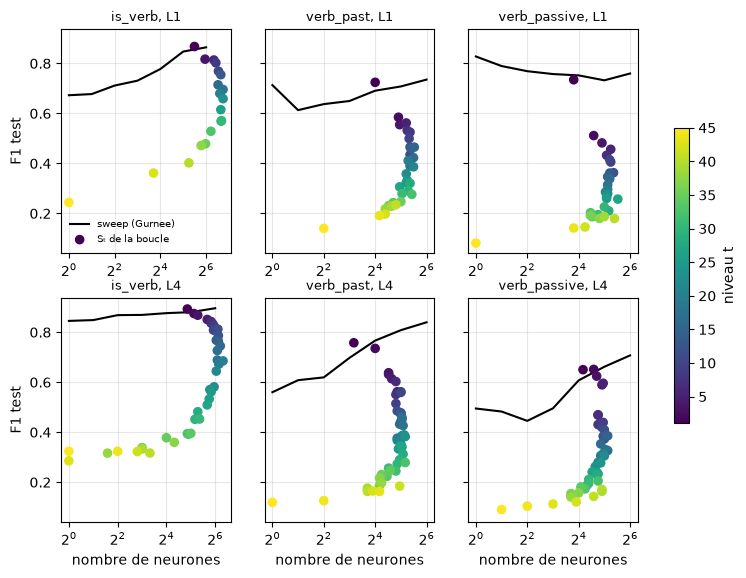

In [15]:
atlas = pd.DataFrame([dict(task=k[0], layer=k[1],
                           K=f"{len(r['supports'])}{'+' if r['hit_max_iter'] else ''}",
                           S1=r["sizes"][0] if r["sizes"] else 0,
                           F1_S1=r["levels"][0]["f1"] if r["levels"] else np.nan,
                           F1_last=r["levels"][-1]["f1"] if r["levels"] else np.nan,
                           F1_meilleur_neurone=r["baseline_k1_f1"], positifs_train=int(r["pos_frac"] * r["n_train"]))
                      for k, r in RES.items()])
display(atlas.pivot_table(index="task", columns="layer",
                          values=["K", "S1", "F1_S1", "F1_last", "F1_meilleur_neurone"],
                          aggfunc="first").round(3))

show = [t for t in TASKS_RUN if not t.endswith("|within")]
fig, axes = plt.subplots(len(LAYERS), len(show), figsize=(3.1 * len(show), 3.2 * len(LAYERS)),
                         squeeze=False, sharey=True)
for i, l in enumerate(LAYERS):
    for j, name in enumerate(show):
        ax = axes[i, j]
        r = RES.get((name, l))
        if r is None:
            ax.set_visible(False)
            continue
        ks = sorted(r["baseline_sweep"])
        ax.plot(ks, [r["baseline_sweep"][k]["f1"] for k in ks], "k-", lw=1.5, label="sweep (Gurnee)")
        sc = ax.scatter(r["sizes"], [v["f1"] for v in r["levels"]], c=range(1, len(r["sizes"]) + 1),
                        cmap="viridis", s=35, zorder=3, label="Sₜ de la boucle")
        ax.set_xscale("log", base=2)
        ax.set_title(f"{name.split('|')[0]}, L{l}", fontsize=9)
        if j == 0:
            ax.set_ylabel("F1 test")
        if i == len(LAYERS) - 1:
            ax.set_xlabel("nombre de neurones")
        ax.grid(alpha=0.3)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.colorbar(sc, ax=axes, label="niveau t", shrink=0.6)
plt.show()

## Test de la hiérarchie : les niveaux supérieurs basculent-ils vers le parent ?

Pour chaque neurone, deux tailles d'effet (d de Cohen), calculées sur tous les mots disponibles :
- **d_parent** : parent contre non-parent (par exemple, verbe contre tout le reste) ;
- **d_enfant|parent** : enfant contre les autres membres du parent (passif contre autres verbes).

La **généralité** d'un neurone vaut $g = \dfrac{|d_{parent}|}{|d_{parent}| + |d_{enfant|parent}|}$ :
- g proche de 1 : le neurone code le **parent** (« c'est un verbe ») sans distinguer l'enfant ;
- g proche de 0 : il code ce qui est **propre à l'enfant** (« c'est un passif »).

**Hypothèse hiérarchique** : pour les tâches *global*, la généralité médiane des neurones de Sₜ augmente avec t. S₁ capte le spécifique, les niveaux suivants se rabattent sur le parent.

**Deux contrôles** pour savoir si la boucle apporte quelque chose :
- **classement univarié** (tirets) : les neurones classés par |d| de la tâche, découpés en blocs successifs de mêmes tailles que S₁, S₂, … Si on observe la même tendance, un simple classement suffit, et la boucle n'apporte rien de plus sur ce point.
- **neurones aléatoires** (pointillés) : la généralité médiane de neurones quelconques.

On trace aussi les tâches *within* (enfant contre autres membres du parent) : les neurones du parent n'y servent à rien, leur généralité doit donc rester basse à tous les niveaux.

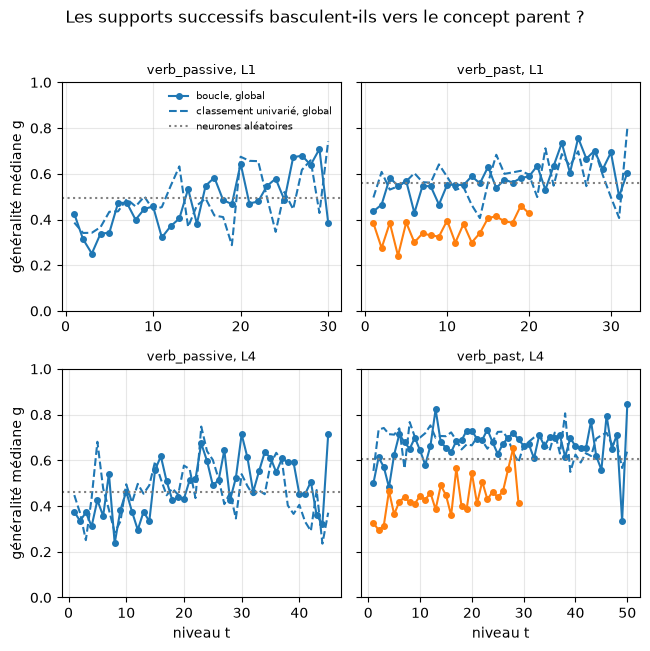

In [16]:
if not CHILDREN_RUN:
    print("Aucune tâche enfant (global/within) dans TASKS_RUN : analyse de généralité sautée.")
else:
    def generality(l, child):
        X = load_layer(l).astype(np.float32)
        X = (X - X.mean(0)) / np.maximum(X.std(0), 1e-3)
        m_child, p = CHILDREN[child]
        m_par = PARENTS[p]
        dp = np.abs(cohen_d(X, m_par))
        dw = np.abs(cohen_d(X[m_par], m_child[m_par]))
        return dp / (dp + dw + 1e-8), dp, dw


    gen_rows = []
    for l in LAYERS:
        for child in CHILDREN_RUN:
            g, dp, dw = generality(l, child)
            rng = np.random.default_rng(SEED)
            rand_med = np.median(g[rng.choice(len(g), 500, replace=False)])
            for framing in ["global", "within"]:
                r = RES.get((f"{child}|{framing}", l))
                if r is None:
                    continue
                # classement univarié de la même tâche, en blocs de mêmes tailles que les S_t
                tr = r["idx_tr"]
                Xtr = load_layer(l)[tr].astype(np.float32)
                ytr = TASKS[f"{child}|{framing}"]["pos"][tr]
                rank = np.argsort(-np.abs(cohen_d(Xtr, ytr)))
                start = 0
                for t, S in enumerate(r["supports"], 1):
                    block = rank[start:start + len(S)]
                    start += len(S)
                    gen_rows.append(dict(layer=l, child=child, framing=framing, t=t,
                                         g_loop=np.median(g[S]), g_rank=np.median(g[block]), g_rand=rand_med,
                                         dpar_loop=np.median(dp[S]), dwithin_loop=np.median(dw[S])))
    gen = pd.DataFrame(gen_rows)
    gen.to_csv(f"{OUT}/generality_by_level.csv", index=False)

    fig, axes = plt.subplots(len(LAYERS), len(CHILDREN_RUN), figsize=(3.3 * len(CHILDREN_RUN), 3.2 * len(LAYERS)),
                             squeeze=False, sharey=True)
    for i, l in enumerate(LAYERS):
        for j, child in enumerate(CHILDREN_RUN):
            ax = axes[i, j]
            for framing, color in [("global", "tab:blue"), ("within", "tab:orange")]:
                g_ = gen[(gen.layer == l) & (gen.child == child) & (gen.framing == framing)]
                if g_.empty:
                    continue
                ax.plot(g_.t, g_.g_loop, "-o", color=color, ms=4, label=f"boucle, {framing}")
                if framing == "global":
                    ax.plot(g_.t, g_.g_rank, "--", color=color, label="classement univarié, global")
                    ax.axhline(g_.g_rand.iloc[0], color="gray", ls=":", label="neurones aléatoires")
            ax.set_title(f"{child}, L{l}", fontsize=9)
            ax.set_ylim(0, 1)
            if j == 0:
                ax.set_ylabel("généralité médiane g")
            if i == len(LAYERS) - 1:
                ax.set_xlabel("niveau t")
            ax.grid(alpha=0.3)
    axes[0, 0].legend(frameon=False, fontsize=7)
    fig.suptitle("Les supports successifs basculent-ils vers le concept parent ?", y=1.01)
    plt.tight_layout()
    plt.show()


## Boucle sur toutes les couches à la fois

Jusqu'ici, la boucle tourne couche par couche, et K est fini dans chaque couche. On met maintenant **les neurones de plusieurs couches côte à côte** dans une seule grande matrice (une ligne par mot, 2 048 colonnes par couche), et on lance la boucle dessus.

**La question.** Les couches portent-elles des encodages **distincts** du concept, ou des **copies** les unes des autres ?
- si K de la grande matrice est proche de la **somme** des K par couche, chaque couche apporte ses propres encodages ;
- s'il est proche du **maximum**, les couches se répètent : un support d'une couche épuise l'information équivalente des autres ;
- la **composition par couche de chaque Sₜ** dit où le concept est le plus accessible en premier, puis quelles couches prennent le relais.

Le λ pivotal augmente avec le nombre de colonnes (le maximum de la référence nulle porte sur plus de neurones), donc chaque support est un peu plus exigeant que dans une couche seule. Comparer aussi le **nombre total de neurones retirés**, pas seulement K.

Cette cellule construit la matrice et affiche ses dimensions. `CAT_LAYERS` choisit les couches ; avec les 6 couches de Pythia-70m, la matrice compte 12 288 colonnes et occupe environ 1,2 Go en mémoire (float16).

In [26]:
CAT_LAYERS = [0, 1, 2, 3, 4, 5]        # couches concaténées (ex. [1, 2, 4] pour une version plus légère)

blocks = [load_layer(l) for l in CAT_LAYERS]
D_MLP = blocks[0].shape[1]
X_CAT = np.concatenate(blocks, axis=1)                       # (n_mots, len(CAT_LAYERS) * D_MLP), float16
del blocks
COL_LAYER = np.repeat(CAT_LAYERS, D_MLP)                     # couche d'origine de chaque colonne
COL_NEURON = np.tile(np.arange(D_MLP), len(CAT_LAYERS))      # indice du neurone dans sa couche

n_train_max = int(N_TASK_MAX * (1 - TEST_FRAC))
print(f"X_CAT : {X_CAT.shape[0]} mots x {X_CAT.shape[1]} neurones ({X_CAT.dtype}), "
      f"{X_CAT.nbytes / 1e9:.2f} Go en mémoire")
for l in CAT_LAYERS:
    cols = np.where(COL_LAYER == l)[0]
    print(f"  couche {l} : colonnes {cols[0]} à {cols[-1]}")
print(f"Jeu d'entraînement d'une tâche : au plus {n_train_max} x {X_CAT.shape[1]}, "
      f"soit {n_train_max * X_CAT.shape[1] * 8 / 1e9:.2f} Go en float64 sur le GPU")
print(f"Référence nulle de la calibration : {N_SIMU} x {X_CAT.shape[1]} valeurs, "
      f"soit {N_SIMU * X_CAT.shape[1] * 8 / 1e9:.2f} Go")

X_CAT : 50000 mots x 12288 neurones (float16), 1.23 Go en mémoire
  couche 0 : colonnes 0 à 2047
  couche 1 : colonnes 2048 à 4095
  couche 2 : colonnes 4096 à 6143
  couche 3 : colonnes 6144 à 8191
  couche 4 : colonnes 8192 à 10239
  couche 5 : colonnes 10240 à 12287
Jeu d'entraînement d'une tâche : au plus 10500 x 12288, soit 1.03 Go en float64 sur le GPU
Référence nulle de la calibration : 2000 x 12288 valeurs, soit 0.20 Go


### Lancer la boucle sur la grande matrice

Même procédure que couche par couche : mêmes tâches (`TASKS_CAT`, par défaut celles de `TASKS_RUN`), même découpage train/test (`task_split`, avec tous les positifs), même baseline (le meilleur neurone seul, ici choisi parmi toutes les couches, sur une validation interne au train), même évaluation de chaque Sₜ.

En plus, pour chaque support, on enregistre **la couche d'origine de chacun de ses neurones**.

**Contrôle nul** (`RUN_NULL_CAT = True`) : la même boucle sur la première tâche avec des labels mélangés. On attend K = 0. Avec 12 288 colonnes, c'est le test le plus exigeant de la calibration.

Les résultats sont enregistrés dans `results/<model>/ewt_concat_<couches>/`, une tâche par fichier ; une tâche déjà calculée est sautée.

**Durée.** Chaque itération coûte environ `len(CAT_LAYERS)` fois plus qu'avec une couche seule, et K peut être plus grand : compter de quelques minutes à une vingtaine de minutes par tâche sur GPU avec les 6 couches. Pour un premier essai, mettre une seule tâche dans `TASKS_CAT`, ou `CAT_LAYERS = [1, 2, 4]`.

In [27]:
TASKS_CAT = list(TASKS_RUN)
MAX_ITER_CAT = 300
RUN_NULL_CAT = True
OUT_CAT = f"results/{MODEL}/ewt_concat_{'-'.join(map(str, CAT_LAYERS))}"
os.makedirs(OUT_CAT, exist_ok=True)


def run_concat(name, shuffle=False):
    tag = name.replace("|", "__") + ("__NULL" if shuffle else "")
    path = f"{OUT_CAT}/{tag}.pkl"
    if os.path.exists(path):
        print(f"{tag} : déjà calculé")
        return
    tr, te, ytr, yte = task_split(name)
    if shuffle:
        rng = np.random.default_rng(SEED + 1)
        ytr, yte = rng.permutation(ytr), rng.permutation(yte)
    Xtr, Xte = X_CAT[tr].astype(np.float32), X_CAT[te].astype(np.float32)
    mu, sd = Xtr.mean(0), np.maximum(Xtr.std(0), 1e-3)
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

    # baseline : meilleur neurone seul parmi toutes les couches, choisi sur une validation interne au train
    d = Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)
    top10 = np.argsort(-np.abs(d))[:10]
    cut = int(0.8 * len(tr))
    f1_val = [f1_score(ytr[cut:], SkLogReg(class_weight="balanced", max_iter=2000)
                       .fit(Xtr[:cut, [j]], ytr[:cut]).predict(Xtr[cut:, [j]])) for j in top10]
    best = int(top10[int(np.argmax(f1_val))])
    baseline = eval_support([best], Xtr, ytr, Xte, yte)

    rec = RecursiveSelection(
        model=LogisticRegression(lambda_=0, penalty=SCADPenalty(), refit=False, dtype="float32"),
        calibrator=BinomialCalibrator(alpha=ALPHA, n_simu=N_SIMU),
        max_iter=MAX_ITER_CAT, progress=True,
    )
    Xfit = torch.tensor(Xtr, device=DEVICE, dtype=torch.float32) if DEVICE == "cuda" else Xtr.astype(np.float32)
    t0 = time.time()
    rec.fit(Xfit, ytr.astype(float))
    fit_s = time.time() - t0
    del Xfit
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    supports = [np.asarray(S, int) for S in rec.supports_]
    levels = [eval_support(S, Xtr, ytr, Xte, yte) for S in supports]
    layer_counts = [{l: int((COL_LAYER[S] == l).sum()) for l in CAT_LAYERS} for S in supports]

    res = dict(task=name, shuffled=shuffle, cat_layers=list(CAT_LAYERS), n_train=len(tr), n_test=len(te),
               n_pos_train=int(ytr.sum()), idx_tr=tr, idx_te=te, supports=supports,
               sizes=[len(S) for S in supports], layer_counts=layer_counts, K=len(supports),
               stopped=len(supports) < MAX_ITER_CAT, levels=levels,
               baseline_best=best, baseline_best_layer=int(COL_LAYER[best]),
               baseline_best_neuron=int(COL_NEURON[best]), baseline=baseline,
               lambdas=np.asarray(getattr(rec, "lambdas_", [])), fit_seconds=fit_s, max_iter=MAX_ITER_CAT)
    with open(path, "wb") as f:
        pickle.dump(res, f)
    s1 = layer_counts[0] if layer_counts else {}
    print(f"{tag} : K = {res['K']} ({'arrêt naturel' if res['stopped'] else 'limite atteinte'}), "
          f"{sum(res['sizes'])} neurones retirés, {fit_s / 60:.1f} min | "
          f"S1 par couche : {s1} | meilleur neurone : L{res['baseline_best_layer']}.N{res['baseline_best_neuron']}")


warnings.filterwarnings("ignore", category=UserWarning)
for name in TASKS_CAT:
    run_concat(name)
if RUN_NULL_CAT:
    run_concat(TASKS_CAT[0], shuffle=True)

Recursive Selection:   0%|          | 0/300 [00:00<?, ?it/s]c:\Users\Utilisateur\Desktop\picpy\picpy\models\_base.py:505: RuntimeWarning: nmAPG: line search from x failed at iteration 116; accepting last trial.
  coef_, intercept_, info = fista(
Recursive Selection:   2%|▏         | 5/300 [00:36<30:32,  6.21s/it, remaining=12116, selected=41]c:\Users\Utilisateur\Desktop\picpy\picpy\models\_base.py:505: RuntimeWarning: nmAPG: line search from y failed at iteration 136; accepting last trial.
  coef_, intercept_, info = fista(
Recursive Selection:   3%|▎         | 8/300 [00:55<30:58,  6.36s/it, remaining=11996, selected=40]c:\Users\Utilisateur\Desktop\picpy\picpy\models\_base.py:505: RuntimeWarning: nmAPG: line search from y failed at iteration 132; accepting last trial.
  coef_, intercept_, info = fista(
Recursive Selection:   4%|▍         | 12/300 [01:28<37:42,  7.86s/it, remaining=11821, selected=48]c:\Users\Utilisateur\Desktop\picpy\picpy\models\_base.py:505: RuntimeWarning: nmAPG: li

is_pron : K = 178 (arrêt naturel), 10478 neurones retirés, 15.6 min | S1 par couche : {0: 6, 1: 4, 2: 4, 3: 1, 4: 2, 5: 1} | meilleur neurone : L1.N907


Recursive Selection:   0%|          | 0/300 [00:00<?, ?it/s]

is_pron__NULL : K = 0 (arrêt naturel), 0 neurones retirés, 0.0 min | S1 par couche : {} | meilleur neurone : L5.N645


### Lecture : profondeur totale et composition par couche

**Le tableau** compare, pour chaque tâche, le K de la grande matrice au K de chaque couche seule (pris dans les résultats couche par couche de `OUT`, s'ils existent pour ces couches), ainsi que le nombre total de neurones retirés. La colonne `K_somme` additionne les K des couches seules disponibles.

**La figure** contient deux panneaux par tâche :
- **à gauche**, la composition par couche de chaque Sₜ (barres empilées, en proportion du support) : on voit quelles couches fournissent les premiers supports, et si les couches s'épuisent l'une après l'autre ou en même temps ;
- **à droite**, l'AUC test de chaque Sₜ, avec celle du meilleur neurone seul (tirets).

,K_concat,arret_naturel,neurones_retires,AUC_S1,AUC_meilleur_neurone,K_L0,K_L1,K_L2,K_L3,K_L4,K_L5,K_somme,K_max
run,,,,,,,,,,,,,
is_pron,178,True,10478,0.998165,0.882002,59.0,27.0,35.0,33.0,37.0,43.0,234.0,59.0
is_pron__NULL,0,True,0,NaN,0.493957,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_verb,132,True,9374,0.995089,0.857165,NaN,19.0,NaN,NaN,40.0,NaN,59.0,40.0
passive_vs_active_participle,58,True,4041,0.993567,0.960460,21.0,21.0,39.0,38.0,39.0,35.0,193.0,39.0
passive_vs_active_participle__NULL,0,True,0,NaN,0.514427,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
past_vs_participle,62,True,3650,0.983294,0.965149,23.0,17.0,29.0,30.0,29.0,24.0,152.0,30.0
past_vs_participle__NULL,0,True,0,NaN,0.489799,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


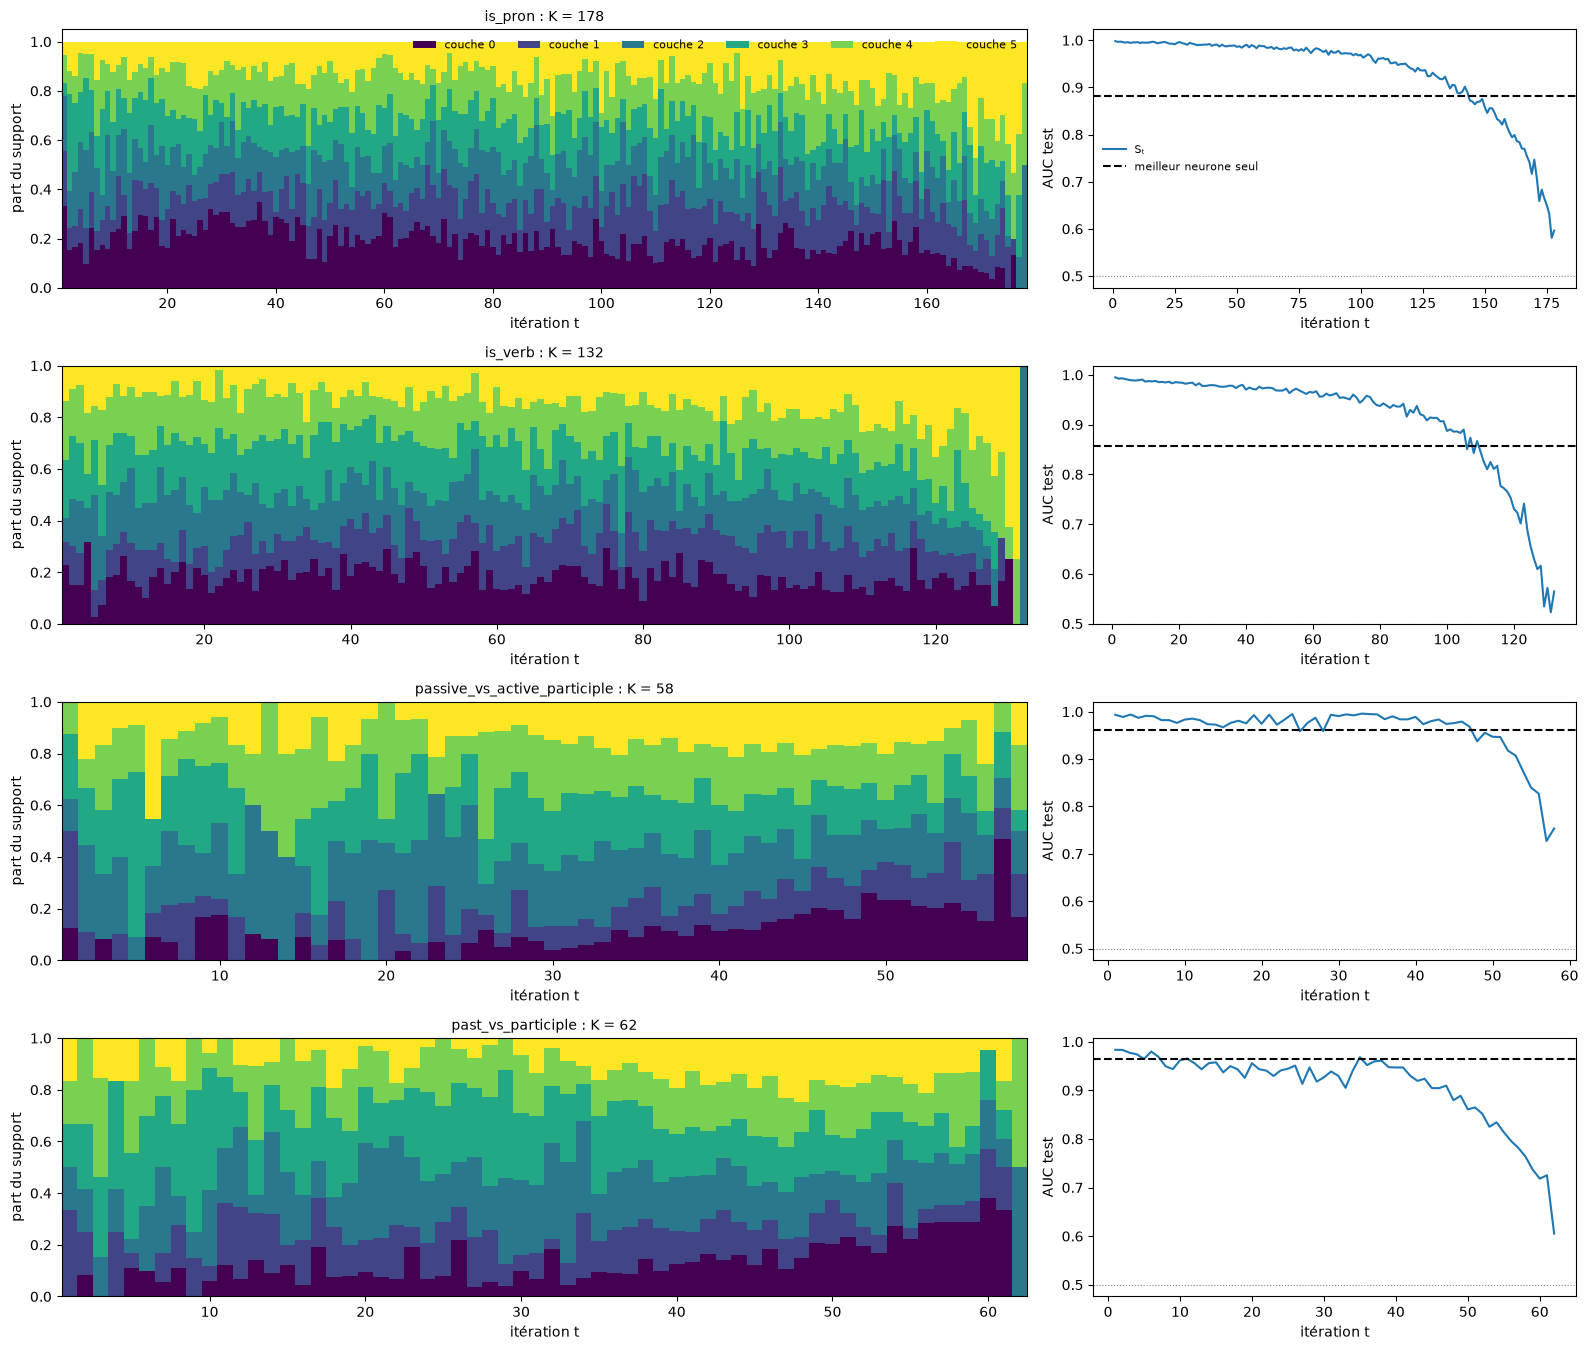

In [28]:
RCAT = {}
for f in sorted(os.listdir(OUT_CAT)):
    if f.endswith(".pkl"):
        with open(f"{OUT_CAT}/{f}", "rb") as fh:
            RCAT[f[:-4]] = pickle.load(fh)

rows = []
for k, r in RCAT.items():
    row = dict(run=k, K_concat=r["K"], arret_naturel=r["stopped"], neurones_retires=int(sum(r["sizes"])),
               AUC_S1=r["levels"][0]["auc"] if r["levels"] else np.nan,
               AUC_meilleur_neurone=r["baseline"]["auc"])
    per_layer = []
    for l in CAT_LAYERS:
        p = result_path(r["task"], l)
        if not r["shuffled"] and os.path.exists(p):
            with open(p, "rb") as fh:
                rl = pickle.load(fh)
            row[f"K_L{l}"] = len(rl["supports"])
            per_layer.append(len(rl["supports"]))
    if per_layer:
        row["K_somme"] = sum(per_layer)
        row["K_max"] = max(per_layer)
    rows.append(row)
display(pd.DataFrame(rows).set_index("run"))

runs = [k for k, r in RCAT.items() if r["K"] > 0]
if runs:
    colors = plt.get_cmap("viridis", len(CAT_LAYERS))
    fig, axes = plt.subplots(len(runs), 2, figsize=(16, 3.4 * len(runs)), squeeze=False,
                             gridspec_kw={"width_ratios": [2, 1]})
    for i, k in enumerate(runs):
        r = RCAT[k]
        t = np.arange(1, r["K"] + 1)
        share = np.array([[c[l] / max(sum(c.values()), 1) for l in CAT_LAYERS] for c in r["layer_counts"]])
        bottom = np.zeros(len(t))
        for j, l in enumerate(CAT_LAYERS):
            axes[i, 0].bar(t, share[:, j], bottom=bottom, color=colors(j), width=1.0, label=f"couche {l}")
            bottom += share[:, j]
        axes[i, 0].set_ylabel("part du support")
        axes[i, 0].set_title(f"{k} : K = {r['K']}{'' if r['stopped'] else ' (limite)'}", fontsize=10)
        axes[i, 0].set_xlim(0.5, len(t) + 0.5)
        axes[i, 1].plot(t, [v["auc"] for v in r["levels"]], color="tab:blue", label="Sₜ")
        axes[i, 1].axhline(r["baseline"]["auc"], color="black", ls="--", label="meilleur neurone seul")
        axes[i, 1].axhline(0.5, color="gray", ls=":", lw=0.8)
        axes[i, 1].set_ylabel("AUC test")
        for a in axes[i]:
            a.set_xlabel("itération t")
    axes[0, 0].legend(frameon=False, fontsize=8, ncol=len(CAT_LAYERS), loc="upper right")
    axes[0, 1].legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()